# Worst-scenario risk and a dual mixture

The supplied theoretical model maximizes mean return minus worst-scenario quadratic risk. It permits shorting; gross exposure is reported rather than hidden. The common riskless asset permits an independent dual upper bound.

See [theory](../docs/theory.md), [protocol](../docs/protocol.md) and [limitations](../docs/model_cards.md).

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
def read(path): return json.loads((ROOT/path).read_text())
def figure(name): display(Image(filename=str(ROOT/'assets/figures'/f'{name}.png')))


## Supplied covariance audit

In [2]:
a=np.load(ROOT/"assets/source_data/convex/portfolio.npz")
matrices=a["scenario_covariances"]
assert np.linalg.eigvalsh(matrices).min()>-1e-10
assert np.allclose(matrices[:,0],0)
print("PSD scenarios with a common riskless asset:",matrices.shape)

PSD scenarios with a common riskless asset: (6, 10, 10)


## Dual weights and exposure

In [3]:
rows=read("results/reference/convex/portfolio/metrics.json")["rows"]
for row in rows:
    assert abs(sum(row["scenario_dual_weights"])-row["gamma"])<1e-8
    assert row["duality_gap"]<1e-6
pd.DataFrame(rows)[["gamma","risk_model","primal_objective","duality_gap","gross_exposure"]]

,gamma,risk_model,primal_objective,duality_gap,gross_exposure
0,0.1,mean_covariance,1.434706,1.315614e-12,83.946146
1,0.1,worst_scenario,1.218808,1.327960e-08,70.676056
2,1.0,mean_covariance,0.143471,1.193212e-13,7.954011
3,1.0,worst_scenario,0.121881,3.578547e-10,7.017249
4,10.0,mean_covariance,0.014347,4.449566e-14,1.695399
5,10.0,worst_scenario,0.012188,4.611211e-10,1.601705


## Declared theoretical tradeoffs

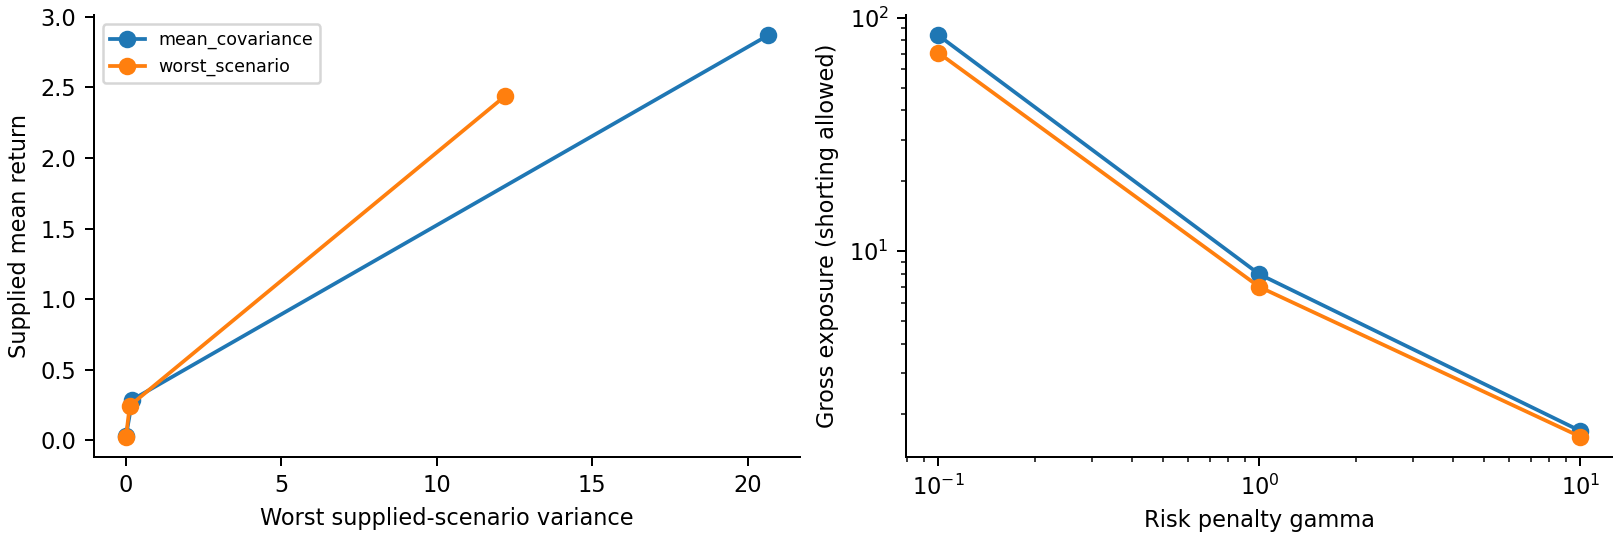

In [4]:
figure("scenario_risk")

Full training / search commands and cache provenance are in [reproduction](../docs/reproduction.md). This notebook inspects actually completed evidence and small analytical checks; opening it does not launch the full fitting campaign.